# Week 3 Helper Notebook

> WARNING: This code was generated as a skeleton for you all and may not work right out of the box. It was developed with assistance from Claude and not fully tested on the eICU dataset. Thus, if something doesn't work, or you see something missing, you should engineer it yourself. This is STARTER code and should not be treated as the final code!!

In this notebook you will train a **Variational Autoencoder (VAE)** on a table with both
**categorical** columns (e.g. diagnoses) and **continuous** columns (e.g. heart rate). 

1. First, naviagate to the `tabular_vae` repository. **Follow the installation structions in the `README.md` for setting up pytorch.** We will also be using Weights and Biases to track model performance. You will need to restart the notebook after installing pytorch / wandb. 


2. Then read thru all the files in the `tabular_vae` folder. You do not need to edit them, but do read them!


| File | Purpose |
|---|---|
| `encoders.py` | [only read if you're doing Project 3] turns one continuous column into `m >= 1` numbers (and back). Put in your code from Week 2! |
| `preprocessing.py` | one-hot encodes categoricals, applies the numerical preprocessinig, builds design matrix per patient |
| `vae.py` | the VAE model and the loss function |

This notebook runs on the **CPU**, no GPU (CUDA) needed.

In [1]:
%load_ext autoreload
%autoreload 2
# This code helps with autoloading new files / modules. 

In [2]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pickle as pk

from IPython.display import display
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from proj34_representation.tabular_vae.encoders import *
from proj34_representation.tabular_vae.vae import TabularVAE, vae_loss
from proj34_representation.tabular_vae.preprocessing import TabularPreprocessor

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

## Step 1: Load eICU data

In [3]:
feature_sets = pk.load(open('../../data/feature_names.pkl', 'rb'))
patient_agg = pd.read_parquet('../../data/clean_dataset.parquet')

print("Dataset shape:", patient_agg.shape)
patient_agg.head()

Dataset shape: (1722, 1099)


,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,hospitaldischargeyear,mortality_at48h,hospital_numbedscategory,hospital_region,"admissiondx_ARDS-adult respiratory distress syndrome, non-cardiogenic pulmonary edema",admissiondx_Abdomen only trauma,admissiondx_Abdomen/extremity trauma,admissiondx_Abdomen/multiple trauma,admissiondx_Ablation or mapping of cardiac conduction pathway,"admissiondx_Abscess, neurologic",admissiondx_Acid-base/electrolyte disturbance,admissiondx_Adrenalectomy,admissiondx_Alcohol withdrawal,admissiondx_Anaphylaxis,admissiondx_Anemia,"admissiondx_Aneurysm, abdominal aortic","admissiondx_Aneurysm, abdominal aortic; with rupture","admissiondx_Aneurysm, dissecting aortic","admissiondx_Aneurysm, thoracic aortic","admissiondx_Aneurysm/pseudoaneurysm, other","admissiondx_Angina, stable (asymp or stable pattern of symptoms w/meds)","admissiondx_Angina, unstable (angina interferes w/quality of life or meds are tolerated poorly)",admissiondx_Aortic and Mitral valve replacement,admissiondx_Aortic valve replacement (isolated),"admissiondx_Apnea, sleep",admissiondx_Appendectomy,"admissiondx_Arrest, respiratory (without cardiac arrest)",admissiondx_Asthma,admissiondx_Atelectasis,"admissiondx_Bleeding, GI from esophageal varices/portal hypertension","admissiondx_Bleeding, GI-location unknown","admissiondx_Bleeding, lower GI","admissiondx_Bleeding, upper GI","admissiondx_Bleeding-other GI, surgery for","admissiondx_Bleeding-upper GI, surgery for",admissiondx_Burr hole placement,"admissiondx_CABG alone, coronary artery bypass grafting",admissiondx_CABG redo with other operation,admissiondx_CABG with aortic valve replacement,admissiondx_CABG with mitral valve repair,admissiondx_CABG with other operation,"admissiondx_CHF, congestive heart failure","admissiondx_CVA, cerebrovascular accident/stroke","admissiondx_Cancer, esophageal","admissiondx_Cancer, oral/sinus, surgery for",...,bicarbonate,calcium,chloride,cortisol,creatinine,direct bilirubin,eos,ethanol,fibrinogen,folate,free T4,glucose,glucose CSF,haptoglobin,ionized calcium,lactate,lipase,lymphs,magnesium,monos,myoglobin,pH,paCO2,paO2,phosphate,platelets x 1000,polys,potassium,prealbumin,prolactin,protein CSF,protein C,protein S,reticulocyte count,salicylate,serum ketones,serum osmolality,sodium,total bilirubin,total cholesterol,total protein,transferrin,triglycerides,troponin I,troponin T,uric acid,urinary creatinine,urinary osmolality,urinary sodium,urinary specific gravity
0,129391,Female,87,Caucasian,59,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,22.0,8.800000,103.000000,NaN,1.180000,NaN,0.5,NaN,NaN,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,14.500000,2.0,7.000000,NaN,NaN,NaN,NaN,NaN,215.0,78.000000,4.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,138.5,0.80,NaN,7.40,NaN,NaN,0.020,NaN,NaN,NaN,NaN,NaN,1.010
1,132209,Male,61,Caucasian,68,2014,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,28.0,9.950000,106.000000,NaN,1.085000,NaN,0.0,NaN,NaN,NaN,NaN,128.5,NaN,NaN,NaN,NaN,194.0,6.500000,1.8,7.500000,NaN,NaN,NaN,NaN,NaN,207.5,83.500000,4.350000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.5,0.80,NaN,6.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.015
2,134042,Female,60,Hispanic,67,2015,0,None,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,38.5,8.200000,98.500000,NaN,0.640000,NaN,0.5,NaN,NaN,NaN,NaN,163.0,NaN,NaN,NaN,1.2,NaN,12.000000,2.0,5.000000,NaN,7.26,74.0,77.25,NaN,207.0,82.500000,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0,0.35,NaN,7.15,NaN,91.0,0.030,NaN,NaN,NaN,NaN,NaN,NaN
3,135537,Female,> 89,Caucasian,60,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,23.0,8.650000,99.000000,NaN,0.680000,NaN,2.0,NaN,NaN,NaN,NaN,98.0,NaN,NaN,NaN,NaN,NaN,13.000000,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,253.0,74.000000,4.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,133.5,0.50,Na

In [4]:
# For privacy, eICU records patients older than 89 using the string "> 89".
# This is how I chose to handle this, but you are free to change it! 
if 'age' in patient_agg.columns:
    patient_agg.loc[patient_agg.age == '> 89', 'age'] = 90
    patient_agg['age'] = patient_agg['age'].astype(float)

In [5]:
import json
X_cols = json.load(open('../../data/x_cols.json'))['all']  # frozen in Week 2
print(f'{len(X_cols)} X columns from Week 2:', X_cols)
df = patient_agg[X_cols]

20 X columns from Week 2: ['age', 'admissionweight', 'heartrate_bin1', 'respiration_bin1', 'sao2_bin1', 'sodium', 'Hgb', 'creatinine', 'BUN', 'glucose', 'WBC x 1000', 'platelets x 1000', 'admissiondx_Sepsis, pulmonary', 'admissiondx_CHF, congestive heart failure', 'admissiondx_Infarction, acute myocardial (MI)', 'admissiondx_Diabetic ketoacidosis', 'admissiondx_Pneumonia, bacterial', 'gender', 'ethnicity', 'hospital_region']


In [6]:
# Run this as is! 

num_cols = [x for x in X_cols if x in
    feature_sets['labs'].tolist()
    + feature_sets['vitals'].tolist()
    + ['age', 'admissionheight', 'admissionweight']
]

bin_cols = [x for x in X_cols if x in 
    feature_sets['icd10_before24h'].tolist()
    + feature_sets['admissiondx'].tolist()
]

cat_cols = [x for x in X_cols if x in [
    'hospital_region',
    'ethnicity',
    'gender',
    'hospital_numbedscategory',
    'hospitaldischargeyear',
    'hospitalid'
]]
cat_cols = bin_cols + cat_cols

In [7]:
# Splits frozen in Week 2 (seed 42, stratified on mortality_at48h):
# train 64% / val 16% / test 20%, loaded from ../../data/splits.json so the
# splits are EXACTLY the same as Week 2, every run.
import json
_splits = json.load(open('../../data/splits.json'))
train_df = patient_agg.iloc[_splits['train']].copy()
val_df = patient_agg.iloc[_splits['val']].copy()
test_df = patient_agg.iloc[_splits['test']].copy()
print({k: len(v) for k, v in [('train', train_df), ('val', val_df), ('test', test_df)]})


{'train': 1101, 'val': 276, 'test': 345}


## Step 1: Detour: Missingness

You may have noticed that variables are often missing in our dataset. For example, age is missing for 0.0346% of all patients, the lab measurement of ANF/ANA is missing for 99.9%, and height is missing for 2%.

Categorical variables can be missing too. For example, if a patient's gender was not recorded.

However, missing values are easier to handle in categorical variables than in continuous ones, because when we one-hot encode the variable, we can simply add one more column for "missing". For example:

|Patient| Recorded gender  | female | male | missing |
|:--|------------------|:------:|:----:|:-------:|
|A| female           |   1    |  0   |    0    |
|B| male             |   0    |  1   |    0    |
|C| *(not recorded)* |   0    |  0   |    1    |

The model treats "missing" like any other category, so it can learn how common it is and even generate it in synthetic data.

The challenge with continuous variables is that we need a numerical input to our model, because NaNs are not valid inputs (a single NaN in a row makes the loss NaN, and then all the weights become NaN too).

**Your goal is to briefly explore and pick one way of handling missingness for continuous variables.** Note, how you define missing values will change how you choose to model continuous variables. Some suggestions are:


1. **Drop the patients** that contain ANY missing value. Simple, but you may throw away a lot of data. 
2. **Fill with a constant**, such as the mean or median (computed on the training set only!). Easy, but many patients now share exactly the same value and the data can lose some predictive power. Use `sklearn.impute.SimpleImputer`. 
4. **Fill with the median and add a "was it missing?" binary variable**, the same trick as for categorical variables. Again use median of training data.
    - Note if you do this: You will need to add on these extra "was missing" variable (# new binary cols = # continuous variables) to the list above of `bin_cols`
6. **Predict the missing value from the other columns** on the training data only (for example a regression, k-nearest neighbors, or a MICE-style imputer such as scikit-learn's `IterativeImputer`). If you use imputation, you are free to use AI to help you impute the dataframe above !!
7. **Multiple imputation.** Fill the gaps several different (random) ways to get several complete datasets, then use a different one in each epoch. If you use imputation, you are free to use AI to help you impute the dataframe above !!


For example, say you build some Imputer class. You would want to do 
```
imp = Imputer()
imp.fit(train_df numerical data)

imputed train = imp.transform(train_df numerical data)
imputed val = imp.transform(val_df numerical data)

```


In [8]:
# Categorical (incl. binary) columns: fill missing with the string "Missing"
# so missingness becomes its own one-hot category (see the markdown above -
# the model can then learn that "not recorded" itself carries information).
imputed_train_df_cat = train_df[cat_cols].copy()
imputed_val_df_cat = val_df[cat_cols].copy()
imputed_test_df_cat = test_df[cat_cols].copy()
for _df in (imputed_train_df_cat, imputed_val_df_cat, imputed_test_df_cat):
    for c in cat_cols:
        _df[c] = _df[c].fillna("Missing")
print("Categorical missing values filled with 'Missing' for",
      len(cat_cols), "columns (train/val/test).")


Categorical missing values filled with 'Missing' for 8 columns (train/val/test).


In [9]:
for c in ['gender', 'ethnicity', 'hospital_region']:
    vc = imputed_train_df_cat[c].value_counts(dropna=False)
    print(f"\n{c} (train):")
    print(vc.head(8))
    print(f"  -> 'Missing' share: {(imputed_train_df_cat[c] == 'Missing').mean():.3f}")



gender (train):
gender
Male       672
Female     428
Missing      1
Name: count, dtype: int64
  -> 'Missing' share: 0.001

ethnicity (train):
ethnicity
Caucasian           860
African American    111
Hispanic             54
Other/Unknown        36
Asian                18
Missing              15
Native American       7
Name: count, dtype: int64
  -> 'Missing' share: 0.014

hospital_region (train):
hospital_region
Midwest      363
South        318
West         245
Missing      112
Northeast     63
Name: count, dtype: int64
  -> 'Missing' share: 0.102


In [10]:
# Numerical strategy chosen: MEDIAN imputation, with medians computed on the
# TRAINING split only (fitting on train only = the Week 2 rule; a val/test
# median would leak). Simple and robust to the heavy skew/outliers in labs.
# (Alternatives - mean, or median + missingness indicator - are Week 6+
# ablation material; the indicator variant is a hypothesis for later.)
num_medians = train_df[num_cols].apply(lambda s: pd.to_numeric(
    s.replace('> 89', 90), errors='coerce').median())
def _impute_num(df):
    out = df[num_cols].copy()
    for c in num_cols:
        out[c] = pd.to_numeric(out[c].replace('> 89', 90), errors='coerce')
    return out.fillna(num_medians)
imputed_train_df_num = _impute_num(train_df)
imputed_val_df_num = _impute_num(val_df)
imputed_test_df_num = _impute_num(test_df)
print("Numerical medians (train):")
print(num_medians.round(2))


Numerical medians (train):
age                  66.00
admissionweight      79.37
heartrate_bin1       84.25
respiration_bin1     18.73
sao2_bin1            96.91
sodium              138.00
Hgb                  12.10
creatinine            1.02
BUN                  19.00
glucose             129.50
WBC x 1000           10.00
platelets x 1000    205.58
dtype: float64


In [11]:
imputed_train_df = pd.concat([imputed_train_df_num, imputed_train_df_cat], axis=1)[X_cols]
imputed_val_df = pd.concat([imputed_val_df_num, imputed_val_df_cat], axis=1)[X_cols]
imputed_test_df = pd.concat([imputed_test_df_num, imputed_test_df_cat], axis=1)[X_cols]

assert imputed_train_df.isnull().sum().sum() == 0, "Train set has missing values after imputation"
assert imputed_val_df.isnull().sum().sum() == 0, "Val set has missing values after imputation"

## Step 2: Let's train a simple VAE model 

In [12]:

# ----------------------- Settings you can play with -----------------------
EPOCHS = 100            # how many passes over the training data
BATCH_SIZE = 256        # rows per gradient update
LEARNING_RATE = 1e-3    # step size of the optimizer
HIDDEN_DIM = 64         # width of the hidden layers
LATENT_DIM = 8          # size of z
BETA = 1.0              # weight of the KL term in the loss
KL_WARMUP_EPOCHS = 10   # BETA grows slowly from ~0 to its full value during these epochs
VAL_FRACTION = 0.2      # share of the data held out for validation
SEED = 42

USE_WANDB = False       # set to True to log to Weights & Biases (needs `pip install wandb` and `wandb login`)
WANDB_PROJECT = "tabular-vae"
# --------------------------------------------------------------------------

torch.manual_seed(SEED)
np.random.seed(SEED)

In [13]:

# By default every continuous column uses StandardEncoder.
# For Proj3: To use another encoder for a column, pass a dictionary where the value
# is an encoder in the encoders.py, for example:
#     cont_encoders = {"age": ModeSpecificEncoder()} You don't need to do this this week though. 
preprocessor = TabularPreprocessor(cat_cols, num_cols, cont_encoders=None)

x_train = preprocessor.fit_transform(imputed_train_df)      # fit on TRAIN only
# FIX (two skeleton traps): (1) the skeleton transformed the UN-dropped df,
# which crashes on unseen categories; (2) drop_unseen() RESETS the index,
# which silently breaks label alignment later. Drop by mask, keep index:
_keep = np.ones(len(imputed_val_df), dtype=bool)
for _c in cat_cols:
    _keep &= imputed_val_df[_c].isin(preprocessor.categories_[_c]).to_numpy()
print(f'Dropped {(~_keep).sum()} val row(s) with unseen categories')
val_pp_df = imputed_val_df[_keep]
x_val = preprocessor.transform(val_pp_df)

print("Number of categories per categorical column:", preprocessor.cat_dims_)
print("Encoded width of each continuous column:    ", preprocessor.cont_dims_)
print(f"Each row has {preprocessor.input_dim_} numbers "
      f"({preprocessor.cat_total_} categorical + {preprocessor.cont_total_} continuous)")
print(f"Rows: {len(x_train)} train, {len(x_val)} validation")
new_cols = preprocessor.get_feature_names()
# A peek at the first 3 preprocessed rows:
pd.DataFrame(x_train[:3],columns=new_cols).round(2)

Dropped 0 val row(s) with unseen categories
Number of categories per categorical column: [2, 2, 2, 2, 2, 3, 7, 5]
Encoded width of each continuous column:     [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Each row has 37 numbers (25 categorical + 12 continuous)
Rows: 1101 train, 276 validation


,"admissiondx_Sepsis, pulmonary=0","admissiondx_Sepsis, pulmonary=1","admissiondx_CHF, congestive heart failure=0","admissiondx_CHF, congestive heart failure=1","admissiondx_Infarction, acute myocardial (MI)=0","admissiondx_Infarction, acute myocardial (MI)=1",admissiondx_Diabetic ketoacidosis=0,admissiondx_Diabetic ketoacidosis=1,"admissiondx_Pneumonia, bacterial=0","admissiondx_Pneumonia, bacterial=1",gender=Female,gender=Male,gender=Missing,ethnicity=African American,ethnicity=Asian,ethnicity=Caucasian,ethnicity=Hispanic,ethnicity=Missing,ethnicity=Native American,ethnicity=Other/Unknown,hospital_region=Midwest,hospital_region=Missing,hospital_region=Northeast,hospital_region=South,hospital_region=West,age,admissionweight,heartrate_bin1,respiration_bin1,sao2_bin1,sodium,Hgb,creatinine,BUN,glucose,WBC x 1000,platelets x 1000
0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.84,-0.50,-0.06,-0.85,0.03,3.16,-0.22,0.09,1.13,0.44,-0.40,0.04
1,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.44,-0.83,-0.23,-0.61,0.58,-0.13,-0.39,-0.06,-0.12,0.59,0.08,0.59
2,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-1.69,-1.09,1.06,0.68,0.84,-1.00,1.69,-0.60,-0.82,1.41,0.41,1.33


In [14]:
# A `DataLoader` hands the data to the model in small random **batches**.
train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(x_val)), batch_size=BATCH_SIZE, shuffle=False)

## 3. The model

Open `vae.py` and read `TabularVAE`. It has an **encoder** (row → `mu`, `logvar`), a sampling step
(`z = mu + sigma * eps`), and a **decoder** (`z` → reconstructed row).

In [15]:
model = TabularVAE(
    input_dim=preprocessor.input_dim_,
    cat_dims=preprocessor.cat_dims_,
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM,
)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(model)
print("Number of trainable parameters:", sum(p.numel() for p in model.parameters()))

TabularVAE(
  (encoder): Sequential(
    (0): Linear(in_features=37, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=8, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=8, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=37, bias=True)
  )
)
Number of trainable parameters: 14773


## 4. The loss function

`vae_loss` (in `vae.py`) adds up **three** terms, each averaged per row:

| Term | Meaning | Formula used |
|---|---|---|
| `recon_cat` | did we reconstruct the categorical variables? | cross-entropy, one per categorical variable |
| `recon_cont` | did we reconstruct the continuous variables? | squared error |
| `kl` | is the latent space close to a standard normal? | KL divergence |

```
loss = recon_cat + recon_cont + beta * kl
```

Below, `run_epoch` does one full pass through a dataset. With an optimizer it **trains**;
without one it only **evaluates** (used for the validation set).

In [16]:
def run_epoch(model, loader, beta, optimizer=None):
    """One pass over `loader`.
    Returns the average per-row recon_cat, recon_cont and kl."""
    training = optimizer is not None
    model.train(training)                         # switches between training and evaluation mode

    sums = {"recon_cat": 0.0, "recon_cont": 0.0, "kl": 0.0}
    n_rows = 0

    with torch.set_grad_enabled(training):        # no gradients needed when just evaluating
        for (x,) in loader:                       # (the skeleton omitted this loop)
            x_hat, mu, logvar = model(x)          # forward pass (see vae.py)
            loss, parts = vae_loss(x, x_hat, mu, logvar, model.cat_dims, beta)
            if training:
                optimizer.zero_grad()             # 1) clear old gradients
                loss.backward()                   # 2) compute new gradients
                optimizer.step()                  # 3) update the weights

            n_rows += x.size(0)
            for name in sums:
                sums[name] += parts[name] * x.size(0)
    return {name: value / n_rows for name, value in sums.items()}


## 5. Train

!! IMPORTANT !! DO NOT use test set to tune hyperparemeters!! (Why?)


Every epoch we train on the training set and then measure the loss on the validation set.

Two details:

* **KL warm-up:** at the start, the KL weight is small and grows to `BETA`. This helps the model learn
  to use `z` before the KL term starts pulling it towards N(0, 1).
* The *logged* total loss always uses the full `BETA`, so the numbers are comparable across epochs.
* We keep a copy of the model from the epoch with the **lowest validation loss**.

In [17]:
if USE_WANDB:
    import wandb
    wandb.init(project=WANDB_PROJECT, config={
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LEARNING_RATE, "hidden_dim": HIDDEN_DIM,
        "latent_dim": LATENT_DIM, "beta": BETA, "kl_warmup_epochs": KL_WARMUP_EPOCHS,
    })


def full_loss(parts):
    return parts["recon_cat"] + parts["recon_cont"] + BETA * parts["kl"]


history = []                         # one dictionary of numbers per epoch
best_val_loss = float("inf")
best_state = None

for epoch in range(1, EPOCHS + 1):
    beta_now = BETA * min(1.0, epoch / max(1, KL_WARMUP_EPOCHS))      # KL warm-up

    train_parts = run_epoch(model, train_loader, beta_now, optimizer)   # learn
    val_parts = run_epoch(model, val_loader, beta_now)                  # just measure

    row = {"epoch": epoch, "train_loss": full_loss(train_parts), "val_loss": full_loss(val_parts)}
    for name in ["recon_cat", "recon_cont", "kl"]:
        row[f"train_{name}"] = train_parts[name]
        row[f"val_{name}"] = val_parts[name]
    history.append(row)

    if USE_WANDB:
        wandb.log(row)

    note = ""
    if row["val_loss"] < best_val_loss:
        best_val_loss = row["val_loss"]
        best_state = copy.deepcopy(model.state_dict())
        note = "  <- best so far"

    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d} | train loss {row['train_loss']:7.3f} | val loss {row['val_loss']:7.3f}"
              f" | val: cat {row['val_recon_cat']:5.3f}, cont {row['val_recon_cont']:5.3f}, kl {row['val_kl']:5.3f}{note}")

model.load_state_dict(best_state)    # go back to the best epoch
history = pd.DataFrame(history)
print(f"\nBest validation loss: {best_val_loss:.3f}")

if USE_WANDB:
    wandb.finish()

epoch   1 | train loss  20.033 | val loss  18.157 | val: cat 7.584, cont 10.509, kl 0.063  <- best so far
epoch   5 | train loss  17.980 | val loss  15.975 | val: cat 5.275, cont 10.500, kl 0.200  <- best so far


epoch  10 | train loss  16.073 | val loss  14.364 | val: cat 3.949, cont 10.322, kl 0.093  <- best so far


epoch  15 | train loss  15.786 | val loss  14.125 | val: cat 3.782, cont 10.014, kl 0.330  <- best so far


epoch  20 | train loss  15.154 | val loss  13.573 | val: cat 3.777, cont 8.900, kl 0.896  <- best so far


epoch  25 | train loss  14.806 | val loss  13.319 | val: cat 3.723, cont 8.472, kl 1.124


...

epoch  65 | train loss  12.759 | val loss  12.315 | val: cat 3.548, cont 6.497, kl 2.270  <- best so far
epoch  70 | train loss  12.688 | val loss  12.387 | val: cat 3.548, cont 6.578, kl 2.262


epoch  75 | train loss  12.494 | val loss  12.130 | val: cat 3.532, cont 6.316, kl 2.282  <- best so far
epoch  80 | train loss  12.443 | val loss  11.856 | val: cat 3.541, cont 5.847, kl 2.469  <- best so far


epoch  85 | train loss  12.282 | val loss  12.238 | val: cat 3.572, cont 6.184, kl 2.481


epoch  90 | train loss  12.098 | val loss  12.084 | val: cat 3.528, cont 5.991, kl 2.565
epoch  95 | train loss  12.046 | val loss  12.079 | val: cat 3.475, cont 6.031, kl 2.574


epoch 100 | train loss  11.957 | val loss  11.872 | val: cat 3.463, cont 5.714, kl 2.694

Best validation loss: 11.584


## 6. Understand the loss curves

* **Train and validation both go down:** the model is learning.
* **Train goes down but validation goes up:** *overfitting* (the model memorizes the training rows).
* **KL close to 0:** *posterior collapse*. The decoder ignores `z`, so generated data will look generic.
  Try a smaller `BETA` or a longer `KL_WARMUP_EPOCHS`.

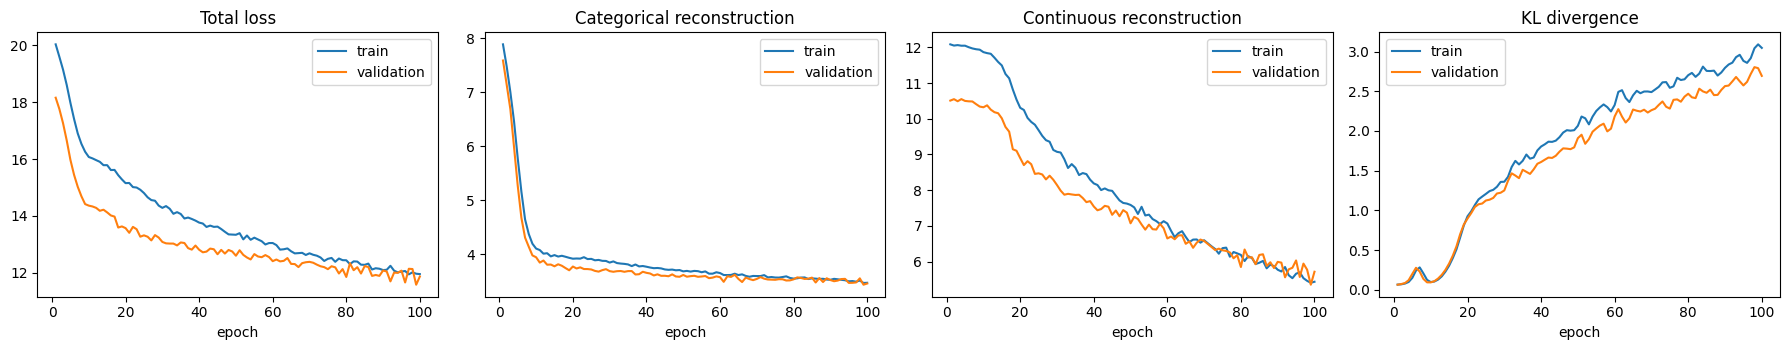

In [18]:
panels = [("loss", "Total loss"),
          ("recon_cat", "Categorical reconstruction"),
          ("recon_cont", "Continuous reconstruction"),
          ("kl", "KL divergence")]

hist_df = pd.DataFrame(history)  # FIX: skeleton indexed the list of dicts directly
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (key, title) in zip(axes, panels):
    ax.plot(hist_df["epoch"], hist_df[f"train_{key}"], label="train")
    ax.plot(hist_df["epoch"], hist_df[f"val_{key}"], label="validation")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Repeat until loss goes down. 

In [19]:
# TODO: keep trying this, debugigng the code, etc. until the loss functions look as they should. 
# For "what should they look like", look at the curves here:
# https://dmol.pub/dl/VAE.html

# If you are having trouble getting your model to work, that's totally ok! 
# "Getting your model to work" means you are now one step closer to being a CS (AI) researcer.
# There are a lot of resources out there (including some I've provided) that can 
# help you figure out what is going on and how to fix it!

In [20]:
# Latent-dim comparison: retrain the same VAE with LATENT_DIM in {2, 8, 32}
# (50 epochs each, everything else identical) and compare val loss terms.
def train_vae(latent_dim, epochs=50):
    torch.manual_seed(SEED); np.random.seed(SEED)
    m = TabularVAE(input_dim=preprocessor.input_dim_, cat_dims=preprocessor.cat_dims_,
                   hidden_dim=HIDDEN_DIM, latent_dim=latent_dim)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)
    best = (float("inf"), None)
    for epoch in range(1, epochs + 1):
        b = BETA * min(1.0, epoch / max(1, KL_WARMUP_EPOCHS))
        run_epoch(m, train_loader, b, opt)
        vp = run_epoch(m, val_loader, b)
        vl = vp["recon_cat"] + vp["recon_cont"] + BETA * vp["kl"]
        if vl < best[0]:
            best = (vl, copy.deepcopy(m.state_dict()))
    m.load_state_dict(best[1])
    vp = run_epoch(m, val_loader, BETA)
    return best[0], vp

rows = []
for ld in [2, 8, 32]:
    vl, vp = train_vae(ld)
    rows.append({"latent_dim": ld, "best_val_loss": round(vl, 3),
                 "val_recon_cat": round(vp["recon_cat"], 3),
                 "val_recon_cont": round(vp["recon_cont"], 3),
                 "val_kl": round(vp["kl"], 3)})
    print(rows[-1])
print("\nReading (actual numbers above): best val loss is nearly FLAT across")
print("latent dims (2: 12.66, 8: 12.60, 32: 12.75) - on 1,101 training rows,")
print("capacity is not the bottleneck, and 50-epoch runs are noisy. Week 4 asks")
print("whether the dims differ on probe / recovery / geometry instead.")


{'latent_dim': 2, 'best_val_loss': 12.66, 'val_recon_cat': 3.599, 'val_recon_cont': 7.628, 'val_kl': 1.432}


{'latent_dim': 8, 'best_val_loss': 12.603, 'val_recon_cat': 3.614, 'val_recon_cont': 7.195, 'val_kl': 1.909}


{'latent_dim': 32, 'best_val_loss': 12.749, 'val_recon_cat': 3.613, 'val_recon_cont': 7.918, 'val_kl': 1.51}

Reading (actual numbers above): best val loss is nearly FLAT across
latent dims (2: 12.66, 8: 12.60, 32: 12.75) - on 1,101 training rows,
capacity is not the bottleneck, and 50-epoch runs are noisy. Week 4 asks
whether the dims differ on probe / recovery / geometry instead.


## Exercise: Are the z's any good?

A common way to check a learned representation is a **linear probe**: if a simple linear model can predict an outcome Y from the latent vector z, then z has captured useful information about x.

1. Pick an outcome Y for every sample (one that was not an input to the VAE).
2. Pass X through the trained encoder and keep the **mean vector `mu`** as z (no sampling).
3. Fit a linear model on the training rows only: **z → Y**. Use linear regression for a continuous Y, or logistic regression for a binary one.
4. Evaluate on the validation rows, using the **same train/validation split** as the VAE.
5. Compare with a linear model trained on **x → Y**. Which does better? Why might z be worse (or better)?

*Bonus:* try different `LATENT_DIM` values. How does probe performance change?

In [21]:
# Y for the probe: mortality_at48h (not an input to the VAE), aligned by the
# original patient_agg index of each split. No missing values after fillna(0).
Y_train = patient_agg.loc[imputed_train_df.index, 'mortality_at48h'].fillna(0).astype(int)
Y_val = patient_agg.loc[val_pp_df.index, 'mortality_at48h'].fillna(0).astype(int)
assert len(Y_train) == len(x_train) and len(Y_val) == len(x_val)
print(f"Probe Y: train deaths={int(Y_train.sum())}/{len(Y_train)}, "
      f"val deaths={int(Y_val.sum())}/{len(Y_val)}")


Probe Y: train deaths=37/1101, val deaths=9/276


In [22]:
from sklearn.metrics import roc_auc_score, average_precision_score

@torch.no_grad()
def get_mu(m, X_matrix):
    m.eval()
    mus = []
    loader = DataLoader(TensorDataset(torch.from_numpy(X_matrix)),
                        batch_size=512, shuffle=False)
    for (xb,) in loader:
        _, mu, _ = m(xb)
        mus.append(mu.numpy())
    return np.vstack(mus)

z_train = get_mu(model, x_train)
z_val = get_mu(model, x_val)
print("z shapes:", z_train.shape, z_val.shape)

probe_z = LogisticRegression(max_iter=1000).fit(z_train, Y_train)
pz = probe_z.predict_proba(z_val)[:, 1]
probe_x = LogisticRegression(max_iter=1000).fit(x_train, Y_train)
px = probe_x.predict_proba(x_val)[:, 1]
print(f"Linear probe z -> Y:  val AUROC={roc_auc_score(Y_val, pz):.3f}  "
      f"AUPRC={average_precision_score(Y_val, pz):.3f}")
print(f"Linear model x -> Y:  val AUROC={roc_auc_score(Y_val, px):.3f}  "
      f"AUPRC={average_precision_score(Y_val, px):.3f}")
print("(x here is the full preprocessed matrix; z is only", z_train.shape[1],
      "numbers per patient - the probe asks how much Y-information survives.)")


z shapes: (1101, 8) (276, 8)


Linear probe z -> Y:  val AUROC=0.480  AUPRC=0.035
Linear model x -> Y:  val AUROC=0.477  AUPRC=0.032
(x here is the full preprocessed matrix; z is only 8 numbers per patient - the probe asks how much Y-information survives.)
